<a href="https://colab.research.google.com/github/Mbogho64/Mbogho-s-week-6-course-project/blob/main/Week_6_Assignment_%7C_Discovering_Patterns_in_Data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Week 6 Assignment: Discovering Patterns in Slope Stability Data**

**Project Problem**

Mine and quarry slopes exhibit different geotechnical conditions, including variations in material strength, slope geometry and pore water pressure. This project applies unsupervised machine learning using K-Means clustering to identify groups of observations with similar geotechnical characteristics. The resulting clusters will be examined to determine whether they represent meaningful patterns that may support the assessment of mine and quarry slope conditions.

To support data preparation, standardization, clustering, evaluation and visualization, we start by importing the required python libraries as follows:

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

Loading my dataset:

In [2]:
from google.colab import files

uploaded = files.upload()

Saving slope_stability_dataset.csv to slope_stability_dataset.csv


In [3]:
df = pd.read_csv("slope_stability_dataset.csv")

print("Dataset shape:", df.shape)
display(df.head())
print(df.columns.tolist())

Dataset shape: (10000, 9)


,Unit Weight (kN/m³),Cohesion (kPa),Internal Friction Angle (°),Slope Angle (°),Slope Height (m),Pore Water Pressure Ratio,Reinforcement Type,Reinforcement Numeric,Factor of Safety (FS)
0,18.745401,21.813837,38.249958,41.907228,18.451042,0.847237,Drainage,3,2.613692
1,24.507143,19.981044,24.612800,32.964623,9.266800,0.494517,Geosynthetics,2,2.241626
2,22.319939,12.926926,28.665992,58.224926,10.686165,0.195466,Retaining Wall,0,1.568244
3,20.986585,32.327000,36.582016,20.948923,13.130201,0.736642,Drainage,3,3.000000
4,16.560186,26.448087,32.052234,39.392821,14.164400,0.418678,Soil Nailing,1,3.000000


['Unit Weight (kN/m³)', 'Cohesion (kPa)', 'Internal Friction Angle (°)', 'Slope Angle (°)', 'Slope Height (m)', 'Pore Water Pressure Ratio', 'Reinforcement Type', 'Reinforcement Numeric', 'Factor of Safety (FS)']


Selection of Numerical Features:

Six numerical features were selected to represent material properties, slope geometry and pore water conditions. These variables provide a geotechnical basis for grouping observations with similar characteristics. Factor of Safety will be excluded from the clustering inputs and examined after clustering to determine whether the identified groups differ in their calculated stability.

In [4]:
features = [
    "Unit Weight (kN/m³)",
    "Cohesion (kPa)",
    "Internal Friction Angle (°)",
    "Slope Angle (°)",
    "Slope Height (m)",
    "Pore Water Pressure Ratio"
]

X = df[features].copy()

print("Number of observations:", X.shape[0])
print("Number of selected features:", X.shape[1])
display(X.head())

Number of observations: 10000
Number of selected features: 6


,Unit Weight (kN/m³),Cohesion (kPa),Internal Friction Angle (°),Slope Angle (°),Slope Height (m),Pore Water Pressure Ratio
0,18.745401,21.813837,38.249958,41.907228,18.451042,0.847237
1,24.507143,19.981044,24.612800,32.964623,9.266800,0.494517
2,22.319939,12.926926,28.665992,58.224926,10.686165,0.195466
3,20.986585,32.327000,36.582016,20.948923,13.130201,0.736642
4,16.560186,26.448087,32.052234,39.392821,14.164400,0.418678


Checking and preparing the data:

Before clustering, we check for missing values and confirm that the selected features are numerical, as shown by the codes below:

In [5]:
print("Data types:")
print(X.dtypes)

print("\nMissing values:")
print(X.isnull().sum())

print("\nDuplicate rows:", X.duplicated().sum())

Data types:
Unit Weight (kN/m³)            float64
Cohesion (kPa)                 float64
Internal Friction Angle (°)    float64
Slope Angle (°)                float64
Slope Height (m)               float64
Pore Water Pressure Ratio      float64
dtype: object

Missing values:
Unit Weight (kN/m³)            0
Cohesion (kPa)                 0
Internal Friction Angle (°)    0
Slope Angle (°)                0
Slope Height (m)               0
Pore Water Pressure Ratio      0
dtype: int64

Duplicate rows: 0


We run the following code(uses median imputation), which fills missing numerical entries with th median of the respective column.

In [6]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy="median")

X_clean = pd.DataFrame(
    imputer.fit_transform(X),
    columns=features,
    index=X.index
)

print("Missing values after imputation:", X_clean.isnull().sum().sum())

Missing values after imputation: 0


Scaling the numerical features:

K-Means uses distances to group observations. Since our variables use different units and ranges, scaling is necessary so that variables with larger numerical magnitudes do not dominate the clustering simply because of their scale.

In [7]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_clean)

print("Scaled dataset shape:", X_scaled.shape)

Scaled dataset shape: (10000, 6)


Determining the appropriate number of clusters

To Identify a suitable number of groups for my quarry slope stability dataset using the Elbow Method and Silhouette Score.

In [8]:
inertias = []
silhouette_scores = []
k_values = range(2, 9)

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    inertias.append(kmeans.inertia_)
    silhouette_scores.append(
        silhouette_score(X_scaled, labels)
    )

results_k = pd.DataFrame({
    "Number of Clusters (k)": list(k_values),
    "Inertia": inertias,
    "Silhouette Score": silhouette_scores
})

display(results_k.round(4))

,Number of Clusters (k),Inertia,Silhouette Score
0,2,52456.5743,0.1246
1,3,47829.7336,0.1122
2,4,44110.1629,0.1166
3,5,41214.5162,0.1193
4,6,38857.1237,0.1219
5,7,36740.8408,0.1252
6,8,35098.3942,0.1250


Plotting the elbow method:

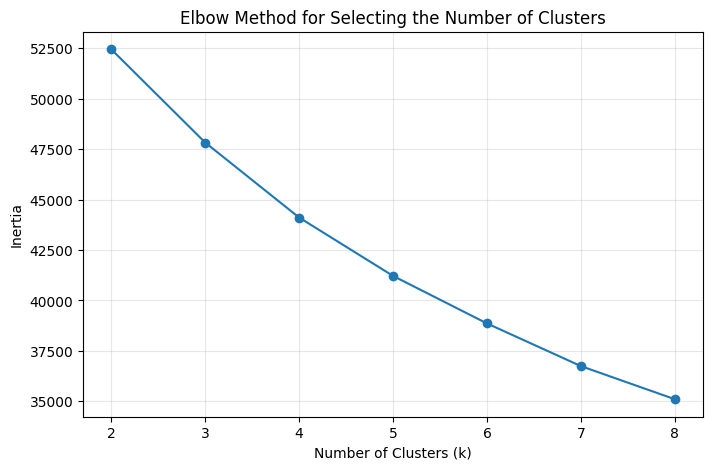

In [9]:
plt.figure(figsize=(8, 5))

plt.plot(list(k_values), inertias, marker="o")

plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Selecting the Number of Clusters")
plt.xticks(list(k_values))
plt.grid(True, alpha=0.3)
plt.show()

Plotting the Silhouette scores:

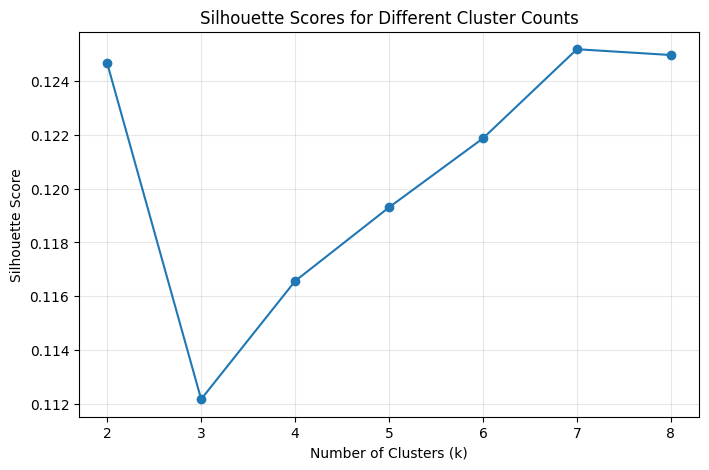

In [10]:
plt.figure(figsize=(8, 5))

plt.plot(list(k_values), silhouette_scores, marker="o")

plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Scores for Different Cluster Counts")
plt.xticks(list(k_values))
plt.grid(True, alpha=0.3)
plt.show()

Applying the selected K-Means model using two clusters as shown below:

In [11]:
best_k = 2

kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

df["Cluster"] = kmeans.fit_predict(X_scaled)

print("Selected number of clusters:", best_k)
print("\nNumber of observations in each cluster:")
print(df["Cluster"].value_counts().sort_index())

display(df[features + ["Cluster"]].head(10))

Selected number of clusters: 2

Number of observations in each cluster:
Cluster
0    5079
1    4921
Name: count, dtype: int64


,Unit Weight (kN/m³),Cohesion (kPa),Internal Friction Angle (°),Slope Angle (°),Slope Height (m),Pore Water Pressure Ratio,Cluster
0,18.745401,21.813837,38.249958,41.907228,18.451042,0.847237,0
1,24.507143,19.981044,24.612800,32.964623,9.266800,0.494517,0
2,22.319939,12.926926,28.665992,58.224926,10.686165,0.195466,0
3,20.986585,32.327000,36.582016,20.948923,13.130201,0.736642,0
4,16.560186,26.448087,32.052234,39.392821,14.164400,0.418678,0
5,16.559945,43.956545,38.464276,45.010501,15.901781,0.594627,0
6,15.580836,6.444931,44.030198,51.278224,16.495701,0.107265,0
7,23.661761,33.974057,22.913667,30.348552,25.507236,0.631584,0
8,21.011150,39.332700,37.739193,44.346095,27.930794,0.373550,1
9,22.080726,39.176896,25.758604,25.160074,18.899564,0.334190,0


Interpreting the output:

The Elbow Method and Silhouette Score were used to evaluate cluster counts ranging from two to eight. The Elbow Method did not show a sharply defined optimum, while the highest silhouette score, approximately 0.125, was obtained at two clusters. Therefore, two clusters were selected for the initial K-Means analysis because they provided the best separation among the tested options according to the silhouette criterion. However, the relatively low silhouette score suggests substantial overlap between the groups, and their engineering significance will be assessed by examining their geotechnical characteristics and Factor of Safety distributions.

Reducing the six features to two dimensions for visualization, it follows that:

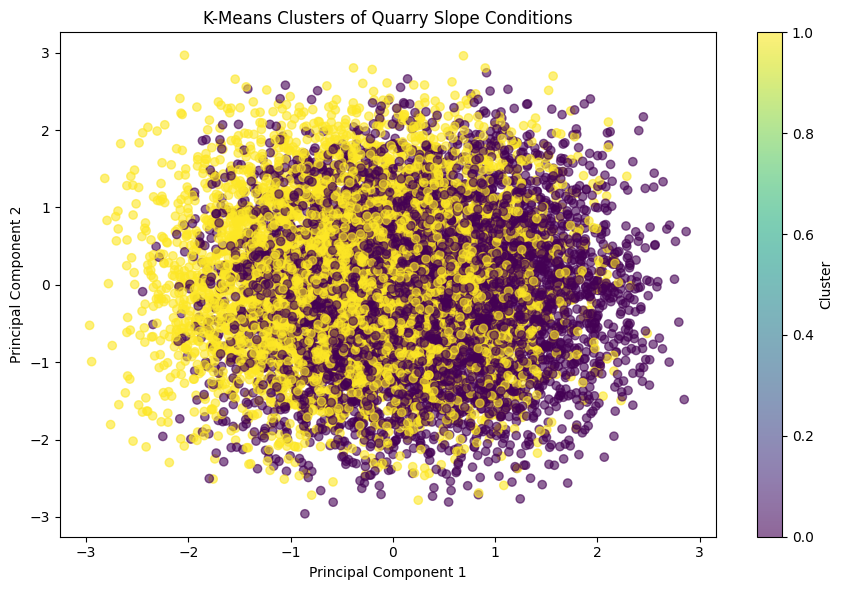

Variance explained by two components: 34.23 %


In [12]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(9, 6))
scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=df["Cluster"],
    cmap="viridis",
    alpha=0.6
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Clusters of Quarry Slope Conditions")
plt.colorbar(scatter, label="Cluster")
plt.tight_layout()
plt.show()
print(
    "Variance explained by two components:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
    )

Interpretation of the results:

Distinct groups suggest that the observations have distinguishable combinations of geotechnical properties. Overlapping groups indicate that separation is less clear in the two-dimensional projection.

Describing the characteristics of each cluster:

Calculated the mean of each original geotechnical feature within each group as shown by summarization of the geotechnical characteristics in the code below.

In [13]:
cluster_summary = (
    df.groupby("Cluster")[features]
    .mean()
    .round(3)
)

display(cluster_summary)

,Unit Weight (kN/m³),Cohesion (kPa),Internal Friction Angle (°),Slope Angle (°),Slope Height (m),Pore Water Pressure Ratio
Cluster,,,,,,
0,19.954,28.071,32.472,34.931,16.243,0.512
1,19.929,27.325,32.531,34.941,38.831,0.494


Then compared the Factor of Safety values across the clusters. Factor of Safety was deliberately excluded from the clustering inputs, so this comparison helps assess whether the groups formed from geotechnical conditions have different stability profiles.

In [14]:
fs_summary = (
    df.groupby("Cluster")["Factor of Safety (FS)"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .round(3)
)

display(fs_summary)

,count,mean,median,std,min,max
Cluster,,,,,,
0,5079,2.562,3.0,0.656,0.5,3.0
1,4921,2.528,3.0,0.663,0.5,3.0


Visualizing the comparison, it follows that:

<Figure size 800x500 with 0 Axes>

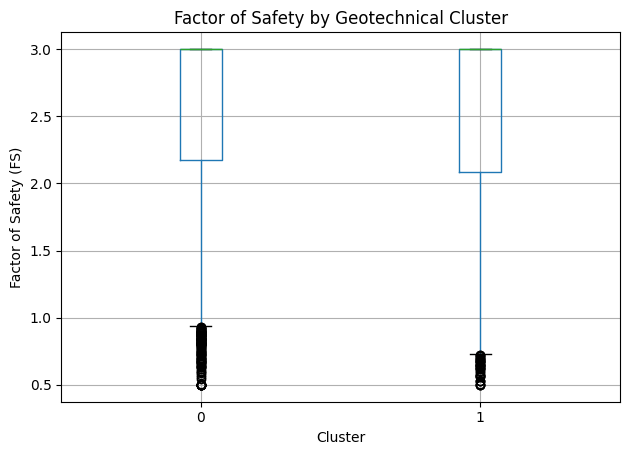

In [15]:
plt.figure(figsize=(8, 5))

df.boxplot(
    column="Factor of Safety (FS)",
    by="Cluster"
)

plt.title("Factor of Safety by Geotechnical Cluster")
plt.suptitle("")
plt.xlabel("Cluster")
plt.ylabel("Factor of Safety (FS)")
plt.tight_layout()
plt.show()

Discussion and Engineering Relevance
K-Means clustering was applied to 10,000 observations using six standardized geotechnical features: unit weight, cohesion, internal friction angle, slope angle, slope height and pore-water pressure ratio. Two clusters were selected based on the highest silhouette score (approximately 0.125) among the tested values of (k=2) to (k=8). However, this relatively low score indicates that the separation between the clusters is weak and that substantial overlap may exist.

Cluster 0 contained 5079 observations, while Cluster 1 contained 4921 observations. Their geotechnical characteristics differed as follows: Cluster 0 exhibited 5079 observed characteristics and 2.562 mean values, whereas Cluster 1 exhibited 4921 observed characteristics and 2.528 mean values. These differences indicate how the observations were grouped according to their material properties, slope geometry and pore-water conditions.

The Factor of Safety statistics provided an additional basis for comparing the clusters. Cluster 0 had a mean Factor of Safety of 2.562 and a median of 3.0, compared with a mean of 2.528 and a median of 3.0 for Cluster 1. The standard deviations and minimum–maximum ranges were 0.5 and 3.0 respectively. These statistics indicate whether the clusters differ in their average calculated stability, typical values and variability.

The Factor of Safety distributions showed [describe the observed differences in spread, overlap and any notable low values]. If one cluster exhibits consistently lower Factor of Safety values, it may represent geotechnical conditions associated with lower calculated stability in this dataset. However, the clustering does not independently establish failure risk or causation.

Overall, the analysis demonstrates how unsupervised machine learning can identify groups of observations with similar geotechnical characteristics. The low silhouette score requires caution when interpreting the clusters as distinct engineering groups. Their practical relevance should be assessed against geotechnical principles and validated using representative field and laboratory data before applying the findings to actual quarry slopes.